In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:

df = pd.read_csv("../Dataset/Cleaned_Netflix_Dataset.csv")

print("Dataset loaded successfully!")
print("Total rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Total rows and columns: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:

print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Missing values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Duplicate rows: 0


In [4]:
# Step 1: Analyze Rating Categories

rating_counts = df["rating"].value_counts()

print("Netflix Content Rating Distribution:")
print(rating_counts)

print("\nMost Common Rating:")
print(rating_counts.idxmax())

print("\nTotal Rating Categories:")
print(df["rating"].nunique())

Netflix Content Rating Distribution:
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

Most Common Rating:
TV-MA

Total Rating Categories:
14


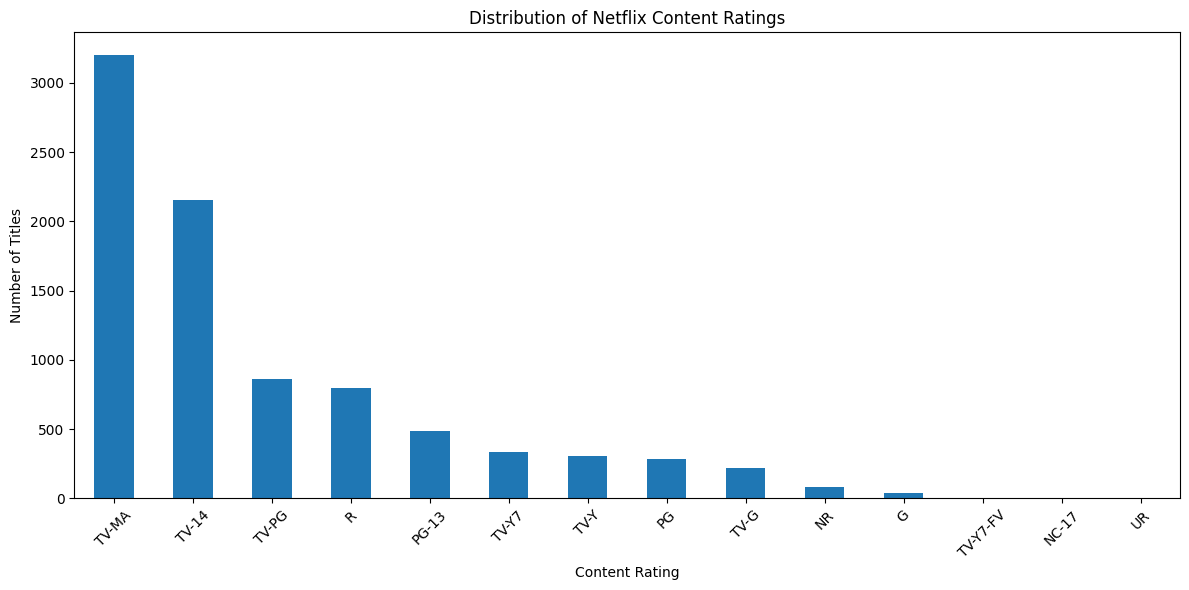

In [5]:
# Visualize Netflix Content Ratings

plt.figure(figsize=(12, 6))

rating_counts.plot(kind="bar")

plt.title("Distribution of Netflix Content Ratings")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../Output/Netflix_Rating_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
# Analyze Netflix Genres

genre_counts = (
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
)

print("Top 10 Netflix Genres:")
print(genre_counts.head(10))

Top 10 Netflix Genres:
listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


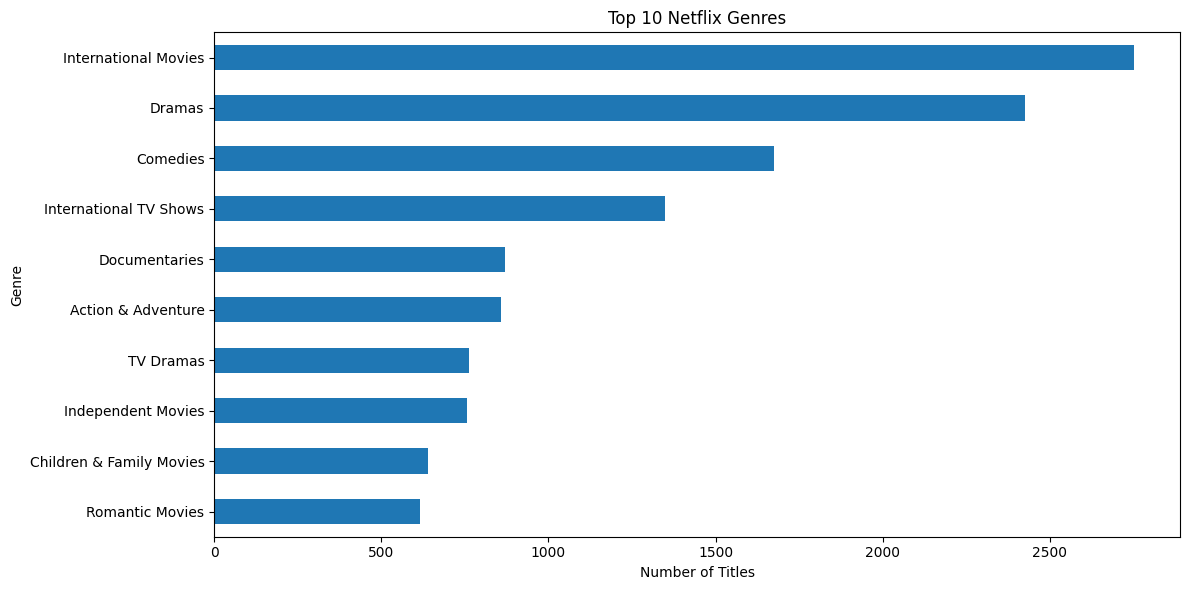

In [8]:
# Visualize Top 10 Netflix Genres

top_genres = genre_counts.head(10)

plt.figure(figsize=(12, 6))

top_genres.sort_values().plot(kind="barh")

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.tight_layout()

plt.savefig(
    "../Output/Netflix_Top_10_Genres.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
# Compare Ratings Across Movies and TV Shows

rating_comparison = pd.crosstab(
    df["rating"],
    df["type"]
)

print("Rating Comparison Across Content Types:")
print(rating_comparison)

Rating Comparison Across Content Types:
type      Movie  TV Show
rating                  
G            41        0
NC-17         3        0
NR           75        4
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      730
TV-G        126       94
TV-MA      2062     1143
TV-PG       540      321
TV-Y        131      175
TV-Y7       139      194
TV-Y7-FV      5        1
UR            3        0


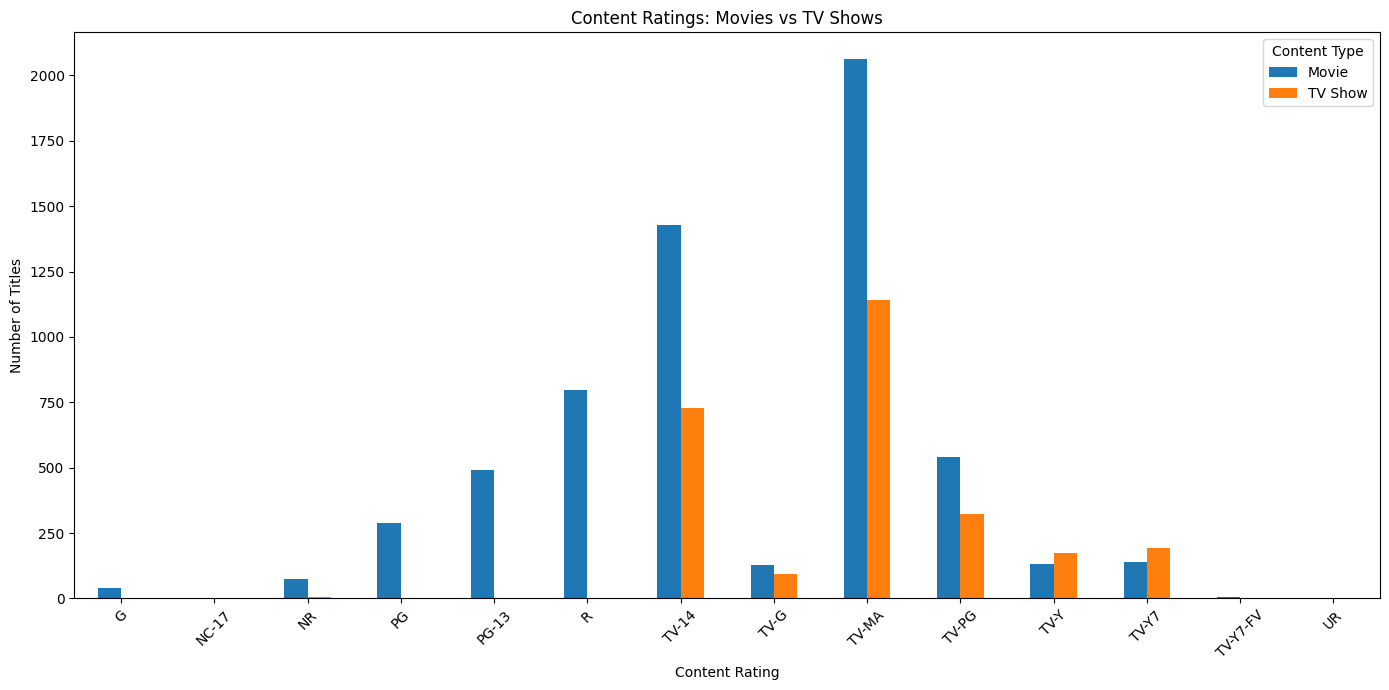

In [10]:
# Visualize Ratings Across Content Types

rating_comparison.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Content Ratings: Movies vs TV Shows")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()

plt.savefig(
    "../Output/Netflix_Ratings_By_Content_Type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
%pip install plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.7 MB 4.4 MB/s eta 0:00:02
   --------- ------------------------------ 2.4/9.7 MB 3.9 MB/s eta 0:00:02
   ------------ --------------------------- 3.1/9.7 MB 4.1 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.7 MB 3.7 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.7 MB 3.3 MB/s eta 0:00:02
   ----------------- ---------------------- 4.2/9.7 MB 3.1 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.7 MB 2.9 MB/s eta 0:00:02
   -------------------- ------------------- 5.0/9.7 MB 2.8 MB/s eta 0:00:02
   --------------------- ------------------ 5.2/9.7 MB 2.7 MB/s eta 0:00:02
   ----------------------- ---------------- 5.8/9.7 MB 2.6 MB/s eta 0:00:02
   ------------------------ --------------- 6.0/9.7 MB 2.5 MB/s eta 0:00:02
   -----------------------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import plotly.express as px
import plotly.io as pio

print("Plotly imported successfully!")


Plotly imported successfully!


In [15]:
%pip install --upgrade nbformat


   -------------------- ------------------- 1/2 [nbformat]
   -------------------- ------------------- 1/2 [nbformat]
   ---------------------------------------- 2/2 [nbformat]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import plotly.express as px

fig = px.bar(
    x=["Movies", "TV Shows"],
    y=[6131, 2676],
    title="Netflix Content Type Distribution"
)

fig.write_html("../Output/Plotly_Test.html")

print("Interactive chart saved successfully!")

Interactive chart saved successfully!


In [18]:
import plotly.express as px

top_genres = genre_counts.head(10).sort_values(ascending=True)

fig_genre = px.bar(
    x=top_genres.values,
    y=top_genres.index,
    orientation="h",
    title="Top 10 Netflix Genres",
    labels={
        "x": "Number of Titles",
        "y": "Genre"
    },
    text=top_genres.values
)

fig_genre.update_layout(
    template="plotly_white",
    title_x=0.5
)

fig_genre.write_html("../Output/Netflix_Top_10_Genres_Interactive.html")

print("Interactive genre chart saved successfully!")

Interactive genre chart saved successfully!


In [19]:
import pandas as pd
import plotly.express as px

# Compare ratings across content types
rating_comparison = pd.crosstab(df["rating"], df["type"])

# Convert the table into a format suitable for Plotly
rating_comparison_long = (
    rating_comparison
    .reset_index()
    .melt(
        id_vars="rating",
        var_name="Content Type",
        value_name="Number of Titles"
    )
)

# Create the interactive chart
fig_rating = px.bar(
    rating_comparison_long,
    x="rating",
    y="Number of Titles",
    color="Content Type",
    barmode="group",
    title="Netflix Content Ratings: Movies vs TV Shows",
    labels={
        "rating": "Content Rating",
        "Number of Titles": "Number of Titles"
    }
)

fig_rating.update_layout(
    template="plotly_white",
    title_x=0.5,
    xaxis_tickangle=-45
)

# Save as an interactive HTML file
fig_rating.write_html(
    "../Output/Netflix_Ratings_Interactive.html"
)

print("Interactive rating comparison chart saved successfully!")

Interactive rating comparison chart saved successfully!


In [2]:
import pandas as pd

# Load the cleaned Netflix dataset
df = pd.read_csv("../Dataset/Cleaned_Netflix_Dataset.csv")

# 1. Analyze content ratings
rating_counts = df["rating"].value_counts()

# 2. Analyze genres
genre_counts = (
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
)

# 3. Compare ratings across content types
rating_comparison = pd.crosstab(df["rating"], df["type"])

# Display audience insights
print("NETFLIX RATING AND GENRE ANALYSIS")
print("=" * 45)

print("\n1. Most Common Content Rating:")
print(f"{rating_counts.idxmax()} - {rating_counts.max()} titles")

print("\n2. Top 3 Genres:")
print(genre_counts.head(3))

print("\n3. Rating Comparison: Movies vs TV Shows")
print(rating_comparison)

print("\n4. KEY AUDIENCE INSIGHTS")
print("-" * 30)
print("- TV-MA is the most common content rating.")
print("- International Movies is the most frequently listed genre.")
print("- Dramas and Comedies are also among the leading genres.")
print("- Movies have more titles than TV Shows in this dataset.")
print("- TV-Y and TV-Y7 ratings appear more frequently for TV Shows than Movies.")

# Save the insights
with open("../Output/Netflix_Audience_Insights.txt", "w", encoding="utf-8") as file:
    file.write("NETFLIX RATING AND GENRE ANALYSIS\n")
    file.write("=" * 45 + "\n\n")
    file.write(f"Most common rating: {rating_counts.idxmax()} ({rating_counts.max()} titles)\n\n")
    file.write("Top 10 Genres:\n")
    file.write(genre_counts.head(10).to_string())
    file.write("\n\nRating Comparison:\n")
    file.write(rating_comparison.to_string())
    file.write("\n\nKEY AUDIENCE INSIGHTS\n")
    file.write("- TV-MA is the most common content rating.\n")
    file.write("- International Movies is the most frequently listed genre.\n")
    file.write("- Dramas and Comedies are among the leading genres.\n")
    file.write("- Movies outnumber TV Shows in this dataset.\n")
    file.write("- TV-Y and TV-Y7 ratings appear more frequently for TV Shows.\n")

print("\nAudience insights saved successfully!")

NETFLIX RATING AND GENRE ANALYSIS

1. Most Common Content Rating:
TV-MA - 3205 titles

2. Top 3 Genres:
listed_in
International Movies    2752
Dramas                  2426
Comedies                1674
Name: count, dtype: int64

3. Rating Comparison: Movies vs TV Shows
type      Movie  TV Show
rating                  
G            41        0
NC-17         3        0
NR           75        4
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      730
TV-G        126       94
TV-MA      2062     1143
TV-PG       540      321
TV-Y        131      175
TV-Y7       139      194
TV-Y7-FV      5        1
UR            3        0

4. KEY AUDIENCE INSIGHTS
------------------------------
- TV-MA is the most common content rating.
- International Movies is the most frequently listed genre.
- Dramas and Comedies are also among the leading genres.
- Movies have more titles than TV Shows in this dataset.
- TV-Y and TV-Y7 ratings appear more frequently for TV Sh